# Horse Colic Survival Prediction

## Introduction

Colic (abdominal pain) is a serious and potentially fatal condition in horses. This notebook prepares the data, explores it and selects the model behind a web service that estimates, from the information available on admission, the probability that a horse with colic will survive.

- **Dataset:** training data from the Kaggle competition [Predict Health Outcomes of Horses](https://www.kaggle.com/competitions/playground-series-s3e22) (Playground Series S3E22), a synthetic dataset derived from the [UCI Horse Colic dataset](https://archive.ics.uci.edu/dataset/47/horse+colic). The data is not included in the repository; see the README for download instructions.
- **Target:** `lived` versus `not lived` (`died` + `euthanized`).
- **Metric:** ROC AUC, because the service returns a probability and AUC measures how well the model ranks horses regardless of the decision threshold. Accuracy and F1 are reported as supporting metrics.

In [64]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, mutual_info_score, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [65]:
# Seed: passed as random_state to every split and model
SEED = 42
np.random.seed(SEED)

In [66]:
# Load the dataset
df = pd.read_csv("data/train.csv")

print(f"{df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

1235 rows and 29 columns


,id,surgery,age,hospital_number,rectal_temp,pulse,respiratory_rate,temp_of_extremities,peripheral_pulse,mucous_membrane,...,packed_cell_volume,total_protein,abdomo_appearance,abdomo_protein,surgical_lesion,lesion_1,lesion_2,lesion_3,cp_data,outcome
0,0,yes,adult,530001,38.1,132.0,24.0,cool,reduced,dark_cyanotic,...,57.0,8.5,serosanguious,3.4,yes,2209,0,0,no,died
1,1,yes,adult,533836,37.5,88.0,12.0,cool,normal,pale_cyanotic,...,33.0,64.0,serosanguious,2.0,yes,2208,0,0,no,euthanized
2,2,yes,adult,529812,38.3,120.0,28.0,cool,reduced,pale_pink,...,37.0,6.4,serosanguious,3.4,yes,5124,0,0,no,lived
3,3,yes,adult,5262541,37.1,72.0,30.0,cold,reduced,pale_pink,...,53.0,7.0,cloudy,3.9,yes,2208,0,0,yes,lived
4,4,no,adult,5299629,38.0,52.0,48.0,normal,normal,normal_pink,...,47.0,7.3,cloudy,2.6,no,0,0,0,yes,lived


## Target

The original `outcome` column has three values: `lived`, `died` and `euthanized`. The service estimates survival, and euthanasia is partly a human decision rather than a purely clinical outcome, so `died` and `euthanized` are grouped into a single class. The new binary target is `lived` (1 = lived, 0 = not lived).

In [67]:
# Binary target: 1 = lived, 0 = died or euthanized
df["lived"] = np.where(df["outcome"] == "lived", 1, 0)
del df["outcome"]

Lived: 46.48%
Not lived: 53.52%


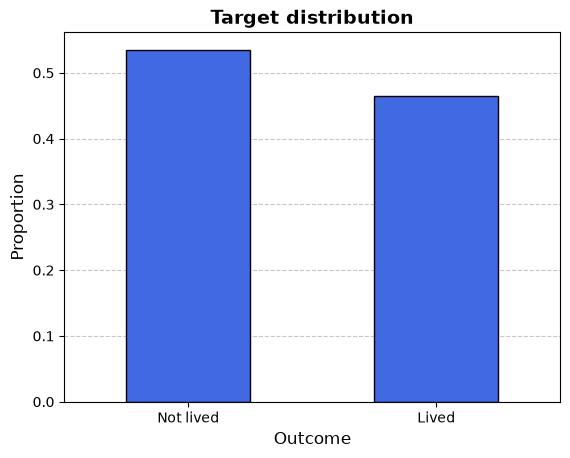

In [68]:
# Target distribution
target_share = df["lived"].value_counts(normalize=True).sort_index()

print(f"Lived: {target_share[1]:.2%}")
print(f"Not lived: {target_share[0]:.2%}")

target_share.plot(kind="bar", color="royalblue", edgecolor="black", zorder=2)
plt.title("Target distribution", fontsize=14, fontweight="bold")
plt.xlabel("Outcome", fontsize=12)
plt.ylabel("Proportion", fontsize=12)
plt.xticks(ticks=[0, 1], labels=["Not lived", "Lived"], rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7, zorder=1)
plt.show()

**Conclusion:** 46.5% of the horses lived and 53.5% did not. The classes are nearly balanced, so no resampling is needed and accuracy remains easy to interpret. A model that always predicts "not lived" already reaches 53.5% accuracy: this is the baseline the models must beat.

## Data cleaning

Cleaning decisions:

1. **Groups:** `hospital_number` is kept aside as `groups` before dropping it, because it is used later to split the data by groups (see the `hospital_number` analysis).
2. **Excluded columns:**
   - `id` and `hospital_number` are identifiers.
   - `cp_data` has no significance according to UCI.
   - `surgical_lesion`, `lesion_1`, `lesion_2` and `lesion_3` are only known after surgery or autopsy, so they would leak future information.
3. **Missing values:** the CSV stores them as the text `None`, which pandas reads as missing. All of them are in categorical columns. They are filled with `"unknown"` as a category of their own, because a test that was not done may itself be informative (analysed in the EDA). This value is different from lowercase `none`, a valid category in columns such as `abdominal_distention`. The numerical columns have no missing values, so they are not imputed; the API will require them.
4. **Rare categories:** five values appear in only one or two rows. They are artefacts of the synthetic generation, so a model cannot learn from them and the API should not accept them:
   - `capillary_refill_time = "3"` is read as a refill time of 3 seconds, which UCI groups with longer times, so it becomes `"more_3_sec"`.
   - `pain = "slight"` is closest to `"mild_pain"`.
   - `nasogastric_reflux = "slight"` is closest to `"less_1_liter"`.
   - `peristalsis = "distend_small"` and `rectal_exam_feces = "serosanguious"` belong to other columns (`abdomen` and `abdomo_appearance`), so they become `"unknown"`.
5. **`total_protein` units:** the values form two separate groups, 3.5–13 and 46–89, with nothing in between. Normal values are around 6–7.5 g/dL, so the high group is most likely in g/L. Values above 30, the middle of the gap, are divided by 10.

In [69]:
# Keep hospital_number aside for the grouped split, then drop the excluded columns
groups = df["hospital_number"]

excluded_columns = ["id", "hospital_number", "cp_data", "surgical_lesion", "lesion_1", "lesion_2", "lesion_3"]
df = df.drop(columns=excluded_columns)

print(f"{df.shape[0]} rows and {df.shape[1]} columns after dropping the excluded columns")

1235 rows and 22 columns after dropping the excluded columns


In [70]:
# Categorical and numerical feature lists
categorical_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_columns = [column for column in df.select_dtypes(include="number").columns if column != "lived"]

print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")
print(f"Numerical columns ({len(numerical_columns)}): {numerical_columns}")

Categorical columns (14): ['surgery', 'age', 'temp_of_extremities', 'peripheral_pulse', 'mucous_membrane', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distention', 'nasogastric_tube', 'nasogastric_reflux', 'rectal_exam_feces', 'abdomen', 'abdomo_appearance']
Numerical columns (7): ['rectal_temp', 'pulse', 'respiratory_rate', 'nasogastric_reflux_ph', 'packed_cell_volume', 'total_protein', 'abdomo_protein']


In [71]:
# Missing values: all in categorical columns, filled with a category of their own
print(f"Missing values before: {df.isna().sum().sum()}")

df[categorical_columns] = df[categorical_columns].fillna("unknown")

print(f"Missing values after: {df.isna().sum().sum()}")

Missing values before: 765
Missing values after: 0


In [72]:
# Value counts of each categorical column, to spot rare categories
for column in categorical_columns:
    print(column, df[column].value_counts().to_dict())

surgery {'yes': 887, 'no': 348}
age {'adult': 1160, 'young': 75}
temp_of_extremities {'cool': 700, 'normal': 324, 'cold': 121, 'warm': 51, 'unknown': 39}
peripheral_pulse {'reduced': 724, 'normal': 429, 'unknown': 60, 'absent': 18, 'increased': 4}
mucous_membrane {'pale_pink': 284, 'normal_pink': 260, 'pale_cyanotic': 250, 'bright_red': 211, 'dark_cyanotic': 121, 'bright_pink': 88, 'unknown': 21}
capillary_refill_time {'less_3_sec': 834, 'more_3_sec': 393, 'unknown': 6, '3': 2}
pain {'depressed': 429, 'mild_pain': 408, 'severe_pain': 146, 'extreme_pain': 120, 'alert': 87, 'unknown': 44, 'slight': 1}
peristalsis {'hypomotile': 664, 'absent': 444, 'normal': 53, 'hypermotile': 53, 'unknown': 20, 'distend_small': 1}
abdominal_distention {'moderate': 543, 'slight': 346, 'none': 212, 'severe': 111, 'unknown': 23}
nasogastric_tube {'slight': 758, 'none': 275, 'significant': 122, 'unknown': 80}
nasogastric_reflux {'more_1_liter': 604, 'none': 331, 'less_1_liter': 278, 'unknown': 21, 'slight': 

In [73]:
# Rare categories (1-2 rows each), artefacts of the synthetic generation
rare_categories = {
    "capillary_refill_time": {"3": "more_3_sec"},
    "pain": {"slight": "mild_pain"},
    "nasogastric_reflux": {"slight": "less_1_liter"},
    "peristalsis": {"distend_small": "unknown"},
    "rectal_exam_feces": {"serosanguious": "unknown"},
}
df = df.replace(rare_categories)

# Smallest category of each column after the replacement
print({column: int(df[column].value_counts().min()) for column in categorical_columns})

{'surgery': 348, 'age': 75, 'temp_of_extremities': 39, 'peripheral_pulse': 4, 'mucous_membrane': 21, 'capillary_refill_time': 6, 'pain': 44, 'peristalsis': 21, 'abdominal_distention': 23, 'nasogastric_tube': 80, 'nasogastric_reflux': 21, 'rectal_exam_feces': 49, 'abdomen': 33, 'abdomo_appearance': 48}


Rows converted from g/L to g/dL: 280
Range after conversion: 3.5 - 13.0


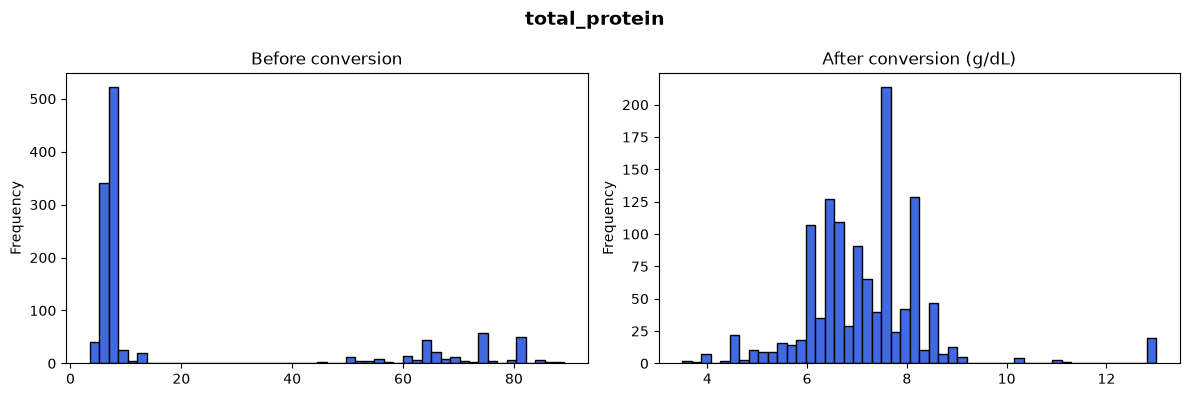

In [74]:
# total_protein mixes g/dL and g/L: no values between 13 and 46
PROTEIN_THRESHOLD = 30

protein_before = df["total_protein"].copy()
df.loc[df["total_protein"] > PROTEIN_THRESHOLD, "total_protein"] /= 10

print(f"Rows converted from g/L to g/dL: {(protein_before > PROTEIN_THRESHOLD).sum()}")
print(f"Range after conversion: {df['total_protein'].min()} - {df['total_protein'].max()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
protein_before.plot(kind="hist", bins=50, ax=axes[0], color="royalblue", edgecolor="black")
axes[0].set_title("Before conversion", fontsize=12)
df["total_protein"].plot(kind="hist", bins=50, ax=axes[1], color="royalblue", edgecolor="black")
axes[1].set_title("After conversion (g/dL)", fontsize=12)
fig.suptitle("total_protein", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Conclusion:** After cleaning, the dataset has 1,235 rows, 21 features (14 categorical and 7 numerical) and no missing values. Missing categorical values are kept as `"unknown"`, the five rare categories are merged into existing ones, and the 280 `total_protein` values in g/L are converted to g/dL, so the column now has a single, clinically plausible range.

## `hospital_number` analysis

According to UCI, `hospital_number` is the case number assigned to a horse, not a hospital. In this synthetic dataset, however, the same value appears in many rows. This section checks how often values repeat and whether rows that share a value also share an outcome.

In [75]:
# How many rows share each hospital_number value
group_sizes = groups.value_counts()

print(f"Distinct values: {groups.nunique()}")
print(f"Values that repeat: {(group_sizes > 1).sum()}")
print(f"Rows per value: min {group_sizes.min()}, max {group_sizes.max()}")

Distinct values: 255
Values that repeat: 198
Rows per value: min 1, max 46


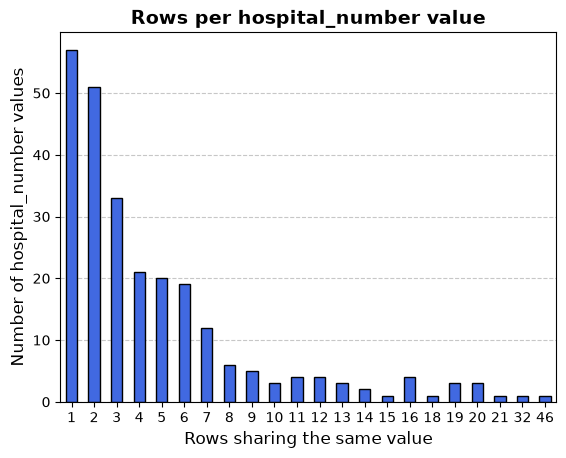

In [76]:
# Distribution of group sizes
group_sizes.value_counts().sort_index().plot(kind="bar", color="royalblue", edgecolor="black", zorder=2)
plt.title("Rows per hospital_number value", fontsize=14, fontweight="bold")
plt.xlabel("Rows sharing the same value", fontsize=12)
plt.ylabel("Number of hospital_number values", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7, zorder=1)
plt.show()

In [77]:
# Groups whose rows have different outcomes
outcomes_per_group = df.groupby(groups)["lived"].nunique()

print(f"Values with mixed outcomes: {(outcomes_per_group > 1).sum()}")

Values with mixed outcomes: 152


**Conclusion:** There are only 255 distinct `hospital_number` values for 1,235 rows; 198 of them repeat, one up to 46 times. In 152 of these groups some horses lived and others did not, so a repeated value does not necessarily mean the same horse: the rows are probably synthetic variations of the same original case. If rows from the same group ended up in both training and validation, the model could recognise near-copies and the metrics would be optimistic. For that reason, every split in this notebook is grouped by `hospital_number`.

## Train, validation and test split

The competition also provides a `test.csv` file, but it has no `outcome` column: its labels are hidden because it is used to score Kaggle submissions. Without labels it cannot be used to evaluate the model, so all three sets are taken from `train.csv`.

The data is split into train (60%), validation (20%) and test (20%) with `StratifiedGroupKFold`, which keeps the class proportions and puts every `hospital_number` value entirely in one of the three sets:

1. 20% of the rows are held out as the test set.
2. A quarter of the remaining 80% (20% of the total) becomes the validation set.

Models are trained on train and compared on validation. The test set is not used until the final evaluation.

In [78]:
# Step 1: hold out 20% of the rows as the test set
y = df["lived"]
test_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
full_train_idx, test_idx = next(test_splitter.split(df, y, groups))

df_full_train = df.iloc[full_train_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)
groups_full_train = groups.iloc[full_train_idx].reset_index(drop=True)
groups_test = groups.iloc[test_idx].reset_index(drop=True)

In [79]:
# Step 2: a quarter of the remaining 80% (20% of the total) becomes the validation set
val_splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, val_idx = next(val_splitter.split(df_full_train, df_full_train["lived"], groups_full_train))

df_train = df_full_train.iloc[train_idx].reset_index(drop=True)
df_val = df_full_train.iloc[val_idx].reset_index(drop=True)
groups_train = groups_full_train.iloc[train_idx].reset_index(drop=True)
groups_val = groups_full_train.iloc[val_idx].reset_index(drop=True)

In [80]:
# Separate the target from the features
y_full_train = df_full_train.pop("lived")
y_train = df_train.pop("lived")
y_val = df_val.pop("lived")
y_test = df_test.pop("lived")

In [81]:
# Size and class balance of each set, and hospital_number values shared between sets
split_summary = pd.DataFrame({
    "set": ["train", "val", "test"],
    "rows": [len(df_train), len(df_val), len(df_test)],
    "share": [len(df_train) / len(df), len(df_val) / len(df), len(df_test) / len(df)],
    "lived": [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary.round(3))

print("Shared hospital_number values:")
print(f"train-val: {len(set(groups_train) & set(groups_val))}, "
      f"train-test: {len(set(groups_train) & set(groups_test))}, "
      f"val-test: {len(set(groups_val) & set(groups_test))}")

,set,rows,share,lived
0,train,740,0.599,0.466
1,val,248,0.201,0.464
2,test,247,0.200,0.462


Shared hospital_number values:
train-val: 0, train-test: 0, val-test: 0


**Conclusion:** The split gives 740 rows for training, 248 for validation and 247 for testing (60/20/20). The share of horses that lived is almost the same in the three sets (46.6%, 46.4% and 46.2%), and no `hospital_number` value appears in more than one set, so validation and test only contain unseen groups.

## Exploratory data analysis

### Numerical features

Ranges, distribution by outcome and AUC of each numerical feature on its own. All the analysis uses the training set only.

In [82]:
# Training set with the target, used by the plots and tables of this section
df_eda = pd.concat([df_train, y_train], axis=1)

df_eda[numerical_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
rectal_temp,740.0,38.14,0.73,35.4,37.8,38.1,38.50,40.8
pulse,740.0,80.14,30.10,30.0,52.0,76.0,100.00,184.0
respiratory_rate,740.0,30.04,17.01,8.0,18.0,24.0,36.00,96.0
nasogastric_reflux_ph,740.0,4.57,1.90,1.0,3.0,5.0,6.50,7.5
packed_cell_volume,740.0,49.25,10.28,23.0,42.0,48.0,55.00,75.0
total_protein,740.0,7.07,1.13,3.5,6.5,7.2,7.60,13.0
abdomo_protein,740.0,3.37,1.65,0.1,2.0,3.2,4.32,10.1


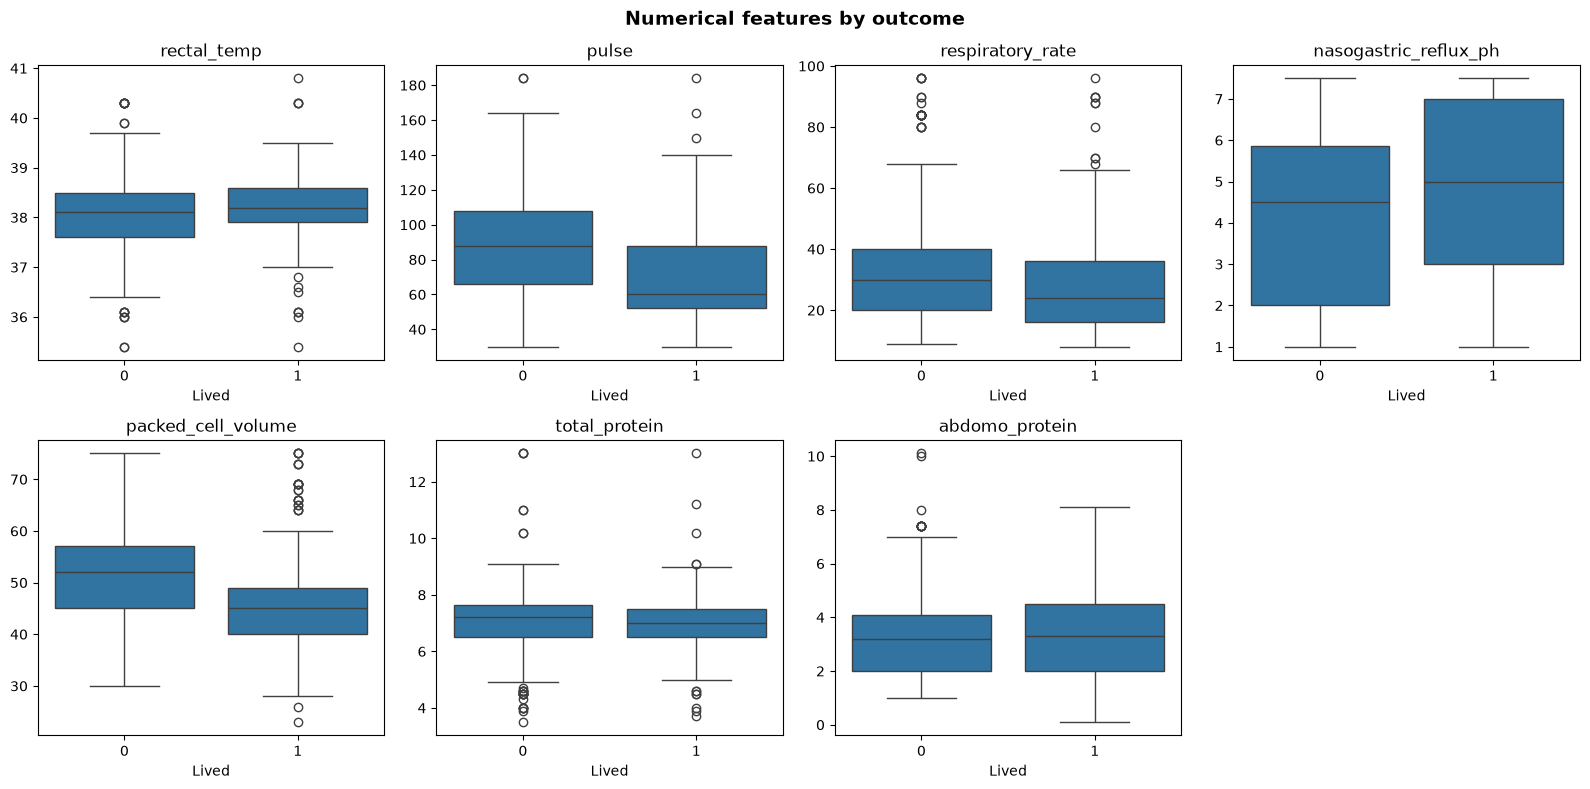

In [83]:
# Distribution of each numerical feature by outcome
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(data=df_eda, x="lived", y=column, ax=ax)
    ax.set_title(column, fontsize=12)
    ax.set_xlabel("Lived")
    ax.set_ylabel("")

for ax in axes[len(numerical_columns):]:
    ax.axis("off")

fig.suptitle("Numerical features by outcome", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [84]:
# AUC of each numerical feature on its own; values below 0.5 are inverted
rows = []
for column in numerical_columns:
    auc = roc_auc_score(y_train, df_train[column])
    rows.append({"feature": column, "auc": max(auc, 1 - auc), "inverted": auc < 0.5})

numerical_auc = pd.DataFrame(rows).sort_values("auc", ascending=False).reset_index(drop=True)
display(numerical_auc.round(3))

,feature,auc,inverted
0,pulse,0.682,True
1,packed_cell_volume,0.680,True
2,respiratory_rate,0.598,True
3,rectal_temp,0.578,False
4,nasogastric_reflux_ph,0.570,False
5,total_protein,0.530,True
6,abdomo_protein,0.523,False


**Conclusion:** `pulse` (AUC 0.68) and `packed_cell_volume` (0.68) separate the classes best, both in the inverse direction: a faster heart rate and a higher packed cell volume (a sign of dehydration) go with lower survival. `respiratory_rate` (0.60) behaves the same way. A higher `rectal_temp` (0.58) and a higher `nasogastric_reflux_ph` (0.57) go with higher survival. `total_protein` and `abdomo_protein` are close to 0.5, so on their own they carry little information.

### Categorical features

Survival rate and risk ratio of each category (survival rate of the category divided by the overall rate), and mutual information between each feature and the target.

In [85]:
# Survival rate and risk ratio of each category
global_rate = y_train.mean()

risk_tables = {}
for column in categorical_columns:
    table = df_eda.groupby(column)["lived"].agg(["mean", "count"])
    table["risk"] = table["mean"] / global_rate
    risk_tables[column] = table

for column, table in risk_tables.items():
    display(table.round(3))

,mean,count,risk
surgery,,,
no,0.603,209,1.293
yes,0.412,531,0.885


,mean,count,risk
age,,,
adult,0.481,693,1.031
young,0.255,47,0.548


,mean,count,risk
temp_of_extremities,,,
cold,0.224,76,0.480
cool,0.357,384,0.765
normal,0.694,219,1.489
unknown,0.520,25,1.115
warm,0.722,36,1.549


,mean,count,risk
peripheral_pulse,,,
absent,0.000,6,0.000
increased,0.500,2,1.072
normal,0.674,282,1.445
reduced,0.333,414,0.715
unknown,0.444,36,0.953


,mean,count,risk
mucous_membrane,,,
bright_pink,0.533,60,1.144
bright_red,0.416,113,0.892
dark_cyanotic,0.240,75,0.515
normal_pink,0.779,149,1.670
pale_cyanotic,0.241,145,0.518
pale_pink,0.492,187,1.055
unknown,0.455,11,0.975


,mean,count,risk
capillary_refill_time,,,
less_3_sec,0.569,496,1.219
more_3_sec,0.258,240,0.554
unknown,0.250,4,0.536


... (4 outputs left out)

,mean,count,risk
nasogastric_reflux,,,
less_1_liter,0.530,166,1.137
more_1_liter,0.388,376,0.833
none,0.549,182,1.179
unknown,0.688,16,1.475


,mean,count,risk
rectal_exam_feces,,,
absent,0.370,284,0.793
decreased,0.538,182,1.155
increased,0.500,26,1.072
normal,0.642,137,1.378
unknown,0.369,111,0.792


,mean,count,risk
abdomen,,,
distend_large,0.387,191,0.831
distend_small,0.451,288,0.968
firm,0.828,58,1.775
normal,0.615,52,1.320
other,0.905,21,1.941
unknown,0.323,130,0.693


,mean,count,risk
abdomo_appearance,,,
clear,0.735,162,1.576
cloudy,0.544,215,1.167
serosanguious,0.300,333,0.644
unknown,0.300,30,0.643


In [86]:
# Mutual information between each categorical feature and the target
rows = []
for column in categorical_columns:
    rows.append({"feature": column, "mutual_info": mutual_info_score(y_train, df_train[column])})

categorical_mi = pd.DataFrame(rows).sort_values("mutual_info", ascending=False).reset_index(drop=True)
display(categorical_mi.round(3))

,feature,mutual_info
0,pain,0.144
1,mucous_membrane,0.075
2,abdomo_appearance,0.064
3,temp_of_extremities,0.064
4,peripheral_pulse,0.059
5,abdominal_distention,0.057
6,peristalsis,0.054
7,abdomen,0.048
8,capillary_refill_time,0.044
9,rectal_exam_feces,0.024


**Conclusion:** `pain` is by far the most informative variable (mutual information 0.144, twice the next one). Alert horses survive 94% of the time (risk 2.03) and those with mild pain 71%, while only 13–15% of horses with severe or extreme pain survive (risk around 0.3). Next come signs of circulatory state:

- `mucous_membrane`: 78% survival with normal pink membranes against 24% with cyanotic ones.
- `abdomo_appearance`: 73% with clear abdominal fluid against 30% with serosanguinous fluid.
- `temp_of_extremities`: around 70% with normal or warm extremities against 22% with cold ones.
- `peripheral_pulse`: none of the 6 horses with an absent pulse survived.

`surgery` shows a clear difference (60% survival without surgery against 41% with it) but low mutual information (0.015), and `age` is the least informative variable: young horses survive less (26% against 48%), but there are only 47 of them.

**Missing values:** the `"unknown"` category is informative. Horses without a recorded `nasogastric_tube` (22% survival, risk 0.47), `abdomen` (32%, risk 0.69) or `rectal_exam_feces` (37%, risk 0.79) survive less than average, while those without `nasogastric_reflux` survive more (69%, but only 16 rows). Since a missing test is associated with the outcome, keeping `"unknown"` as its own category is better than imputing the most frequent value.

### Correlation

Pearson correlation between the numerical features.

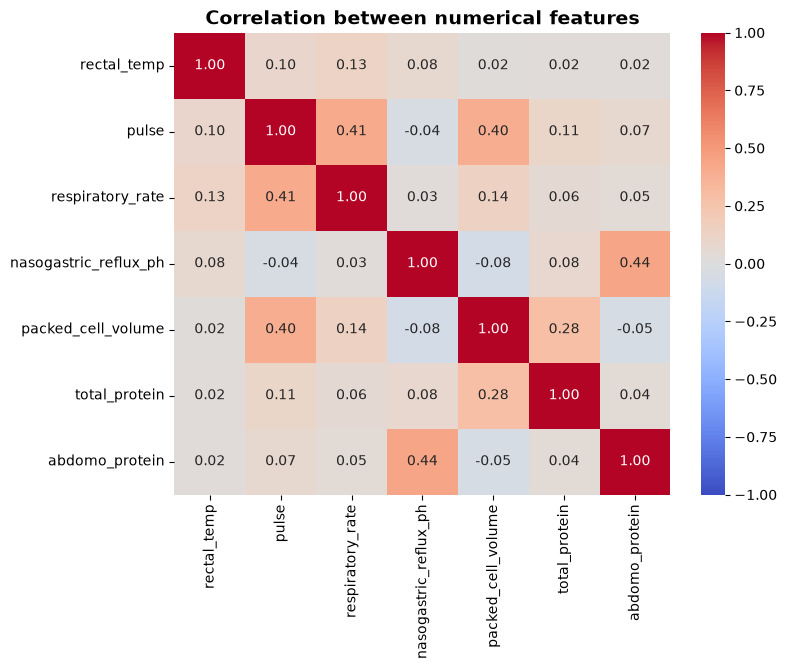

In [87]:
# Correlation between numerical features
plt.figure(figsize=(8, 6))
sns.heatmap(df_train[numerical_columns].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numerical features", fontsize=14, fontweight="bold")
plt.show()

**Conclusion:** No pair of numerical features is strongly correlated. The highest values are moderate: `nasogastric_reflux_ph` with `abdomo_protein` (0.44), and `pulse` with `respiratory_rate` (0.41) and with `packed_cell_volume` (0.40), which is consistent with these three reflecting how severe the circulatory shock is. Every feature brings some information of its own, so none is removed; with correlations this low, multicollinearity is not a concern even for logistic regression.

### Summary

The most informative features, combining the AUC of the numerical features and the mutual information of the categorical ones, are:

1. `pain`: the strongest single predictor.
2. `pulse` and `packed_cell_volume`: higher values mean lower survival.
3. `mucous_membrane`, `temp_of_extremities` and `peripheral_pulse`: signs of poor circulation go with lower survival.
4. `abdomo_appearance`: serosanguinous abdominal fluid goes with lower survival.
5. `abdominal_distention` and `peristalsis`: severe distention and absent gut sounds go with lower survival.

`age`, `nasogastric_tube`, `nasogastric_reflux`, `total_protein` and `abdomo_protein` carry little information on their own, but they are kept: tree-based models can still use them in combination with other features.

## Validation and surgery

### Evaluation setup

The models receive the features as a list of dictionaries, as in the course, so that `DictVectorizer` one-hot encodes the categorical ones. `evaluate` trains a model on one set and returns its ROC AUC, accuracy and F1 on another. The base model is a logistic regression with default regularisation.

In [88]:
# Features and conversion to the list of dictionaries expected by DictVectorizer
features = numerical_columns + categorical_columns


def to_dicts(data, columns):
    return data[columns].to_dict(orient="records")

In [89]:
# Training and evaluation helpers
METRICS = ["roc_auc", "accuracy", "f1_score"]


def evaluate(model, df_tr, y_tr, df_va, y_va, columns):
    """Train on (df_tr, y_tr) and return ROC AUC, accuracy and F1 on (df_va, y_va)."""
    model.fit(to_dicts(df_tr, columns), y_tr)
    y_pred = model.predict_proba(to_dicts(df_va, columns))[:, 1]
    return {
        "roc_auc": roc_auc_score(y_va, y_pred),
        "accuracy": accuracy_score(y_va, y_pred >= 0.5),
        "f1_score": f1_score(y_va, y_pred >= 0.5),
    }


def print_metrics(label, results):
    print(f"{label}: " + ", ".join(f"{metric} {results[metric]:.3f}" for metric in METRICS))

In [90]:
# Base model: logistic regression with default regularisation
base_model = make_pipeline(
    DictVectorizer(sparse=False),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED),
)

### Grouped versus random split

The base model is evaluated on the grouped split and on a random split of the same rows (also 75/25), to check whether rows that share a `hospital_number` make a random split optimistic.

In [91]:
# Base model on the grouped split
base_results = evaluate(base_model, df_train, y_train, df_val, y_val, features)
print_metrics("Grouped split", base_results)

KeyboardInterrupt: 

In [ ]:
# Same model on a random split of the same rows, ignoring hospital_number
df_train_random, df_val_random, y_train_random, y_val_random = train_test_split(
    df_full_train, y_full_train, test_size=0.25, random_state=SEED, stratify=y_full_train)

random_results = evaluate(base_model, df_train_random, y_train_random, df_val_random, y_val_random, features)
print_metrics("Random split", random_results)

Random split: roc_auc 0.773, accuracy 0.717, f1_score 0.670


**Conclusion:** With the same model and the same amount of data, a random split gives a higher AUC (0.773) than the grouped split (0.751). The gap is modest, and with a single validation set of about 250 rows part of it may be noise, but it goes in the direction expected if rows of the same `hospital_number` group are near-copies: a random split lets the model see relatives of the validation rows during training. The grouped split is kept because it is the conservative choice and matches how the service will be used, on horses the model has never seen.

### `surgery`

The base model is evaluated with and without `surgery`, a treatment decision rather than an admission measurement.

In [ ]:
# Base model with and without surgery
features_no_surgery = [column for column in features if column != "surgery"]

no_surgery_results = evaluate(base_model, df_train, y_train, df_val, y_val, features_no_surgery)
print_metrics("With surgery", base_results)
print_metrics("Without surgery", no_surgery_results)

With surgery: roc_auc 0.751, accuracy 0.681, f1_score 0.658
Without surgery: roc_auc 0.752, accuracy 0.685, f1_score 0.661


**Conclusion:** Removing it leaves the AUC unchanged (0.752 without it against 0.751 with it), so it adds no predictive value once the clinical signs are known. It is also a treatment decision rather than an admission measurement: when the veterinarian uses the service, whether the horse will have surgery is usually not decided yet. For both reasons `surgery` is dropped, and from here on the models use the remaining 20 features.

In [ ]:
# Final feature list for the rest of the notebook (without surgery)
features = features_no_surgery
print(f"{len(features)} features: {features}")

20 features: ['rectal_temp', 'pulse', 'respiratory_rate', 'nasogastric_reflux_ph', 'packed_cell_volume', 'total_protein', 'abdomo_protein', 'age', 'temp_of_extremities', 'peripheral_pulse', 'mucous_membrane', 'capillary_refill_time', 'pain', 'peristalsis', 'abdominal_distention', 'nasogastric_tube', 'nasogastric_reflux', 'rectal_exam_feces', 'abdomen', 'abdomo_appearance']


## Models

Four models are compared: logistic regression (linear) and three tree-based models (decision tree, random forest and XGBoost). Each one is trained on the training set and evaluated on the validation set with the `evaluate` function, using the same 20 features. Logistic regression and the decision tree are tuned one hyperparameter at a time; for the random forest and XGBoost, whose hyperparameters interact, all combinations of a small grid are evaluated. Because the validation set is small (248 rows), differences in AUC below 0.01 are treated as ties, and the simpler option is preferred. For each model, one cell builds the pipeline, one runs each tuning loop and one plots its results; the chosen configuration is stored in `best`.

In [ ]:
# Helpers shared by all models
best = {}  # chosen configuration of each model


def show_results(table, top=None):
    """Display a results table with rounded metrics, optionally only the top rows by AUC."""
    if top is not None:
        table = table.nlargest(top, "roc_auc")
    display(table.round({metric: 3 for metric in METRICS}))


def plot_auc(table, param, title):
    """Line plot of the validation AUC for each value of one hyperparameter."""
    plt.figure(figsize=(6, 4))
    plt.plot([str(value) for value in table[param]], table["roc_auc"], marker="o", color="royalblue")
    plt.title(title, fontsize=14, fontweight="bold")
    plt.xlabel(param, fontsize=12)
    plt.ylabel("Validation ROC AUC", fontsize=12)
    plt.grid(linestyle="--", alpha=0.7)
    plt.show()


def plot_auc_heatmaps(table, facet, index, columns, title, index_order=None):
    """One heatmap of the validation AUC per value of `facet`."""
    facet_values = table[facet].unique()
    fig, axes = plt.subplots(1, len(facet_values), figsize=(5 * len(facet_values), 4), sharey=True)
    for ax, value in zip(axes, facet_values):
        pivot = table[table[facet] == value].pivot(index=index, columns=columns, values="roc_auc")
        if index_order is not None:
            pivot = pivot.loc[index_order]
        sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", cbar=False, ax=ax,
                    vmin=table["roc_auc"].min(), vmax=table["roc_auc"].max())
        ax.set_title(f"{facet} = {value}", fontsize=12)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


def save_best(name, model, params):
    """Evaluate the chosen configuration on validation and store it in `best`."""
    best[name] = {"model": model, "params": params,
                  **evaluate(model, df_train, y_train, df_val, y_val, features)}
    print_metrics(name, best[name])

### Baseline

A model that always predicts the most frequent class (`not lived`) sets the minimum that any useful model must beat.

In [ ]:
# Baseline: always predicts the most frequent class
baseline = make_pipeline(
    DictVectorizer(sparse=False),
    DummyClassifier(strategy="most_frequent"),
)
save_best("Baseline", baseline, "strategy=most_frequent")

Baseline: roc_auc 0.500, accuracy 0.536, f1_score 0.000


**Conclusion:** The baseline has an AUC of 0.5, since it gives every horse the same score, and an accuracy of 0.536, the share of `not lived` in the validation set. Its F1 is 0 because it never predicts `lived`.

### Logistic regression

Same pipeline as the base model (one-hot encoding, scaling and logistic regression). The tuned hyperparameter is `C`, the inverse of the regularisation strength: small values force simpler models with smaller coefficients.

In [ ]:
# Logistic regression pipeline
def make_logreg(C):
    return make_pipeline(
        DictVectorizer(sparse=False),
        StandardScaler(),
        LogisticRegression(C=C, max_iter=1000, random_state=SEED),
    )

In [ ]:
# Tuning: C
rows = []
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    results = evaluate(make_logreg(C), df_train, y_train, df_val, y_val, features)
    rows.append({"C": C, **results})

logreg_results = pd.DataFrame(rows)
show_results(logreg_results)

,C,roc_auc,accuracy,f1_score
0,0.0001,0.792,0.645,0.397
1,0.0010,0.791,0.750,0.705
2,0.0100,0.781,0.730,0.697
3,0.1000,0.758,0.690,0.664
4,1.0000,0.752,0.685,0.661
5,10.0000,0.751,0.685,0.661
6,100.0000,0.751,0.685,0.661


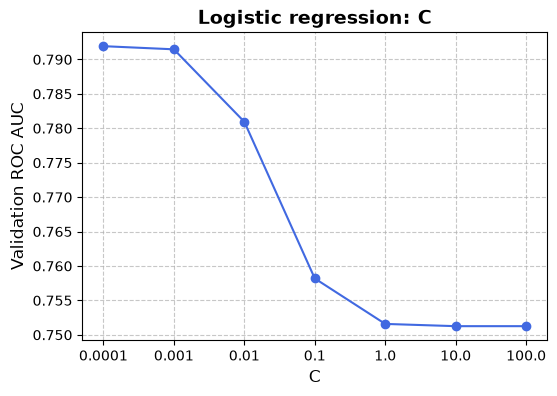

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc(logreg_results, "C", "Logistic regression: C")

**Conclusion:** The AUC rises as `C` decreases, so strong regularisation helps: with 740 rows and about 60 one-hot columns, a weakly regularised model overfits. The AUC peaks around 0.79 for `C` = 0.001 and 0.0001, but with `C` = 0.0001 accuracy and F1 collapse (0.645 and 0.397): the coefficients are so small that almost every probability stays close to 0.5, and the 0.5 threshold misclassifies many horses. `C` = 0.001 keeps the same AUC (0.791) with a good accuracy (0.750) and F1 (0.705), so it is the chosen value.

In [ ]:
# Chosen configuration
save_best("Logistic regression", make_logreg(0.001), "C=0.001")

Logistic regression: roc_auc 0.791, accuracy 0.750, f1_score 0.705


### Decision tree

Trees do not need scaling, so the pipeline is one-hot encoding plus the tree. First `max_depth` is tuned, which limits how many splits a path can have; then, with the best depth, `min_samples_leaf`, the minimum number of horses in each leaf. Both control overfitting.

In [ ]:
# Decision tree pipeline
def make_tree(max_depth, min_samples_leaf=1):
    return make_pipeline(
        DictVectorizer(sparse=False),
        DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED),
    )

In [ ]:
# Tuning: max_depth
rows = []
for max_depth in [2, 3, 4, 5, 6, 8, 10, None]:
    results = evaluate(make_tree(max_depth), df_train, y_train, df_val, y_val, features)
    rows.append({"max_depth": str(max_depth), **results})

tree_depth_results = pd.DataFrame(rows)
show_results(tree_depth_results)

,max_depth,roc_auc,accuracy,f1_score
0,2,0.766,0.726,0.730
1,3,0.775,0.742,0.731
2,4,0.754,0.669,0.655
3,5,0.738,0.706,0.684
4,6,0.708,0.673,0.652
5,8,0.673,0.690,0.675
6,10,0.650,0.677,0.649
7,None,0.627,0.633,0.581


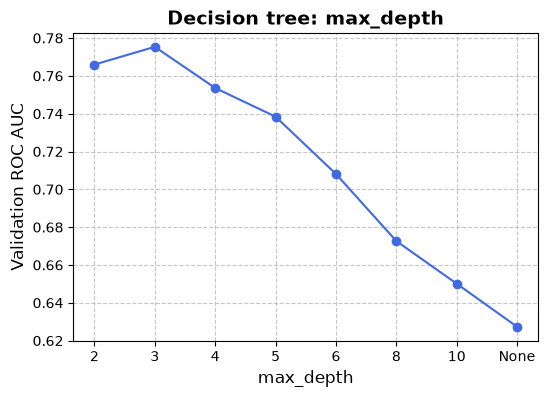

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc(tree_depth_results, "max_depth", "Decision tree: max_depth")

In [ ]:
# Tuning: min_samples_leaf, with max_depth=3
rows = []
for min_samples_leaf in [1, 5, 10, 20, 50]:
    results = evaluate(make_tree(3, min_samples_leaf), df_train, y_train, df_val, y_val, features)
    rows.append({"min_samples_leaf": min_samples_leaf, **results})

tree_leaf_results = pd.DataFrame(rows)
show_results(tree_leaf_results)

,min_samples_leaf,roc_auc,accuracy,f1_score
0,1,0.775,0.742,0.731
1,5,0.775,0.742,0.731
2,10,0.775,0.742,0.731
3,20,0.776,0.742,0.731
4,50,0.772,0.710,0.705


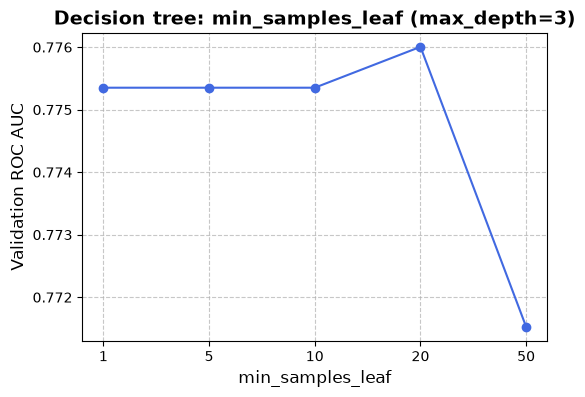

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc(tree_leaf_results, "min_samples_leaf", "Decision tree: min_samples_leaf (max_depth=3)")

**Conclusion:** A depth of 3 gives the best AUC (0.775). Deeper trees overfit quickly: the AUC falls steadily and reaches 0.627 with no depth limit. With `max_depth` = 3, `min_samples_leaf` barely matters (0.772–0.776), because leaves of a tree this shallow already contain many horses. `min_samples_leaf` = 20 is chosen: it ties with the best value and is the more conservative option.

In [ ]:
# Chosen configuration
save_best("Decision tree", make_tree(3, 20), "max_depth=3, min_samples_leaf=20")

Decision tree: roc_auc 0.776, accuracy 0.742, f1_score 0.731


### Random forest

An ensemble of decision trees, each trained on a bootstrap sample of the rows and a random subset of the features, whose predictions are averaged. Because its three main hyperparameters interact, all combinations of `n_estimators` (number of trees), `max_depth` and `min_samples_leaf` are evaluated (64 models), and the results are shown as one heatmap per number of trees.

In [ ]:
# Random forest pipeline
def make_rf(n_estimators, max_depth, min_samples_leaf=1):
    return make_pipeline(
        DictVectorizer(sparse=False),
        RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=SEED,
            n_jobs=-1,
        ),
    )

In [ ]:
# Tuning: grid of n_estimators, max_depth and min_samples_leaf
rows = []
for n_estimators in [50, 100, 200, 300]:
    for max_depth in [3, 5, 10, None]:
        for min_samples_leaf in [1, 3, 5, 10]:
            results = evaluate(make_rf(n_estimators, max_depth, min_samples_leaf),
                               df_train, y_train, df_val, y_val, features)
            rows.append({"n_estimators": n_estimators, "max_depth": str(max_depth),
                         "min_samples_leaf": min_samples_leaf, **results})

rf_results = pd.DataFrame(rows)
show_results(rf_results, top=5)

,n_estimators,max_depth,min_samples_leaf,roc_auc,accuracy,f1_score
60,300,None,1,0.832,0.762,0.733
44,200,None,1,0.829,0.758,0.730
62,300,None,5,0.827,0.754,0.721
58,300,10,5,0.827,0.762,0.731
42,200,10,5,0.827,0.758,0.727


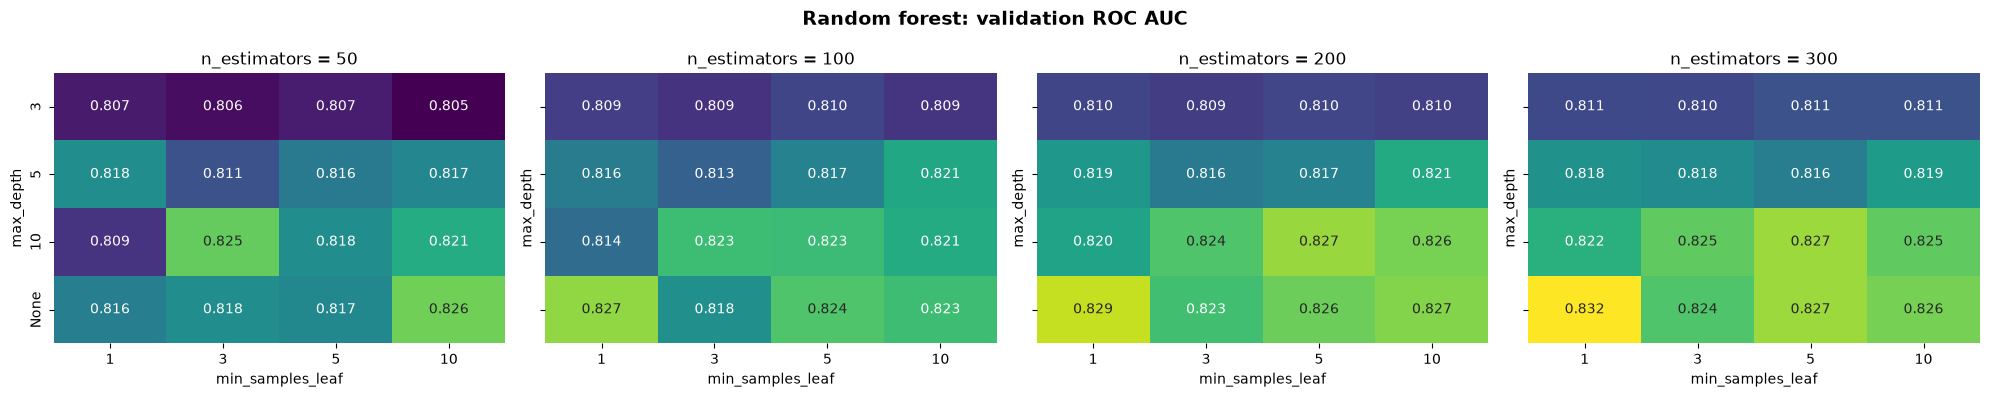

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc_heatmaps(rf_results, facet="n_estimators", index="max_depth", columns="min_samples_leaf",
                  title="Random forest: validation ROC AUC", index_order=["3", "5", "10", "None"])

**Conclusion:** `max_depth` has the largest effect: trees limited to depth 3 stay around 0.81, while depth 10 or no limit reach 0.82–0.83. More trees help slightly up to 200 and then the AUC flattens, and `min_samples_leaf` barely matters. Many combinations fall between 0.82 and 0.83, a range within the noise of a 248-row validation set, so the chosen model is not the single highest value (0.832 with 300 trees and no depth limit) but a simpler one in that range: 200 trees, `max_depth` = 10 and `min_samples_leaf` = 5, with an AUC of 0.827.

In [ ]:
# Chosen configuration
save_best("Random forest", make_rf(200, 10, 5), "n_estimators=200, max_depth=10, min_samples_leaf=5")

Random forest: roc_auc 0.827, accuracy 0.758, f1_score 0.727


### XGBoost

Gradient boosting: trees are added one after another, each correcting the errors of the previous ones. `XGBClassifier` is used because it fits in the same scikit-learn pipeline. First all combinations of `learning_rate` (eta, how much each tree contributes), `max_depth` and `min_child_weight` (minimum weight of the samples in a leaf) are evaluated with 200 boosting rounds (36 models). Then, with the best combination, the number of rounds (`n_estimators`) is tuned.

In [ ]:
# XGBoost pipeline
def make_xgb(learning_rate, max_depth, min_child_weight, n_estimators=200):
    return make_pipeline(
        DictVectorizer(sparse=False),
        XGBClassifier(
            learning_rate=learning_rate,
            max_depth=max_depth,
            min_child_weight=min_child_weight,
            n_estimators=n_estimators,
            eval_metric="logloss",
            random_state=SEED,
            n_jobs=-1,
        ),
    )

In [ ]:
# Tuning: grid of learning_rate, max_depth and min_child_weight, with 200 rounds
rows = []
for learning_rate in [0.01, 0.05, 0.1, 0.3]:
    for max_depth in [3, 4, 6]:
        for min_child_weight in [1, 5, 10]:
            results = evaluate(make_xgb(learning_rate, max_depth, min_child_weight),
                               df_train, y_train, df_val, y_val, features)
            rows.append({"learning_rate": learning_rate, "max_depth": max_depth,
                         "min_child_weight": min_child_weight, **results})

xgb_results = pd.DataFrame(rows)
show_results(xgb_results, top=5)

,learning_rate,max_depth,min_child_weight,roc_auc,accuracy,f1_score
24,0.10,6,1,0.825,0.758,0.737
2,0.01,3,10,0.825,0.754,0.726
8,0.01,6,10,0.824,0.734,0.708
11,0.05,3,10,0.824,0.750,0.721
5,0.01,4,10,0.823,0.754,0.724


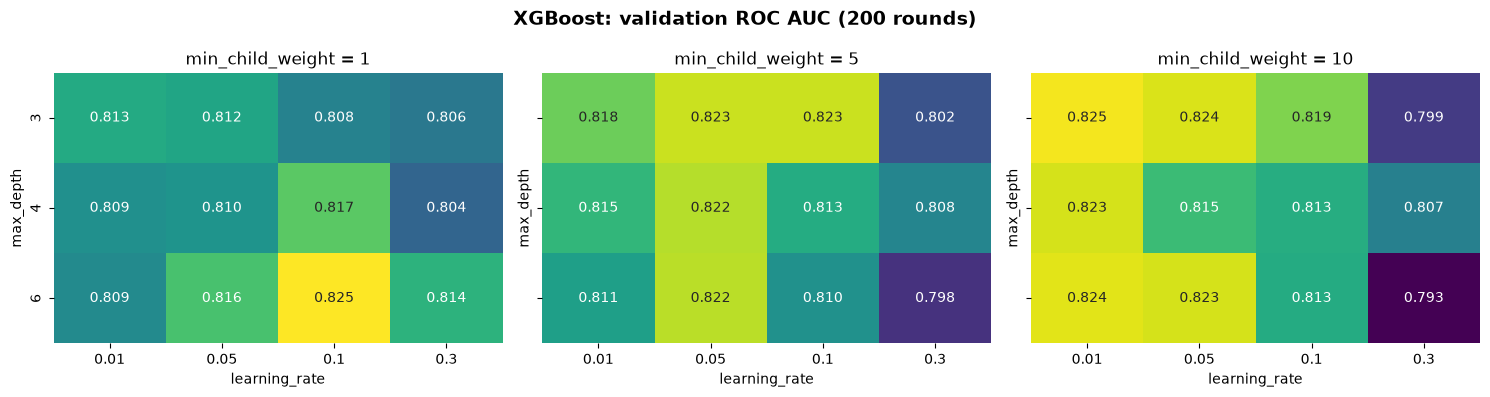

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc_heatmaps(xgb_results, facet="min_child_weight", index="max_depth", columns="learning_rate",
                  title="XGBoost: validation ROC AUC (200 rounds)")

In [ ]:
# Tuning: n_estimators, with learning_rate=0.05, max_depth=3 and min_child_weight=10
rows = []
for n_estimators in [50, 100, 200, 400, 800]:
    results = evaluate(make_xgb(0.05, 3, 10, n_estimators), df_train, y_train, df_val, y_val, features)
    rows.append({"n_estimators": n_estimators, **results})

xgb_rounds_results = pd.DataFrame(rows)
show_results(xgb_rounds_results)

,n_estimators,roc_auc,accuracy,f1_score
0,50,0.826,0.754,0.724
1,100,0.818,0.750,0.723
2,200,0.824,0.750,0.721
3,400,0.821,0.746,0.722
4,800,0.814,0.726,0.702


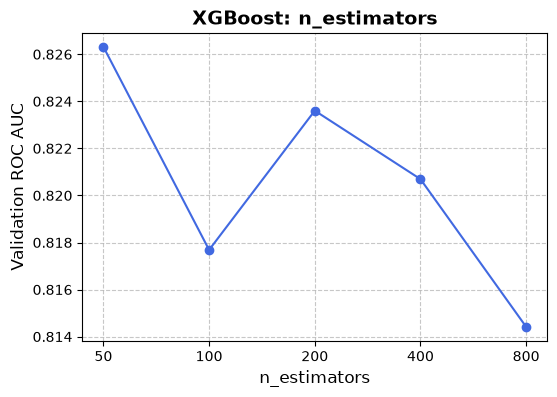

In [ ]:
# Validation AUC for each hyperparameter value
plot_auc(xgb_rounds_results, "n_estimators", "XGBoost: n_estimators")

**Conclusion:** A high `learning_rate` (0.3) gives the worst results (0.79–0.81), and `min_child_weight` = 10, the strongest regularisation tested, works best overall. As with the random forest, the top combinations are within a few thousandths of each other. `learning_rate` = 0.05, `max_depth` = 3 and `min_child_weight` = 10 is chosen: it is among the best (0.824) and stays stable when the number of rounds changes. The number of rounds hardly matters between 50 and 400 (0.818–0.826) and the AUC drops with 800, a sign of overfitting, so the 200 rounds used in the grid are kept.

In [ ]:
# Chosen configuration
save_best("XGBoost", make_xgb(0.05, 3, 10, 200),
          "learning_rate=0.05, max_depth=3, min_child_weight=10, n_estimators=200")

XGBoost: roc_auc 0.824, accuracy 0.750, f1_score 0.721


## Model comparison

The chosen configuration of each model is first compared on the validation set. Because a single validation set of 248 rows is noisy, the ranking is then checked on five different grouped splits of the training and validation data. The test set is still not used.

### Validation results

In [ ]:
# Validation metrics of the chosen configuration of each model
comparison_results = pd.DataFrame(
    [{"model": name, "params": entry["params"], **{metric: entry[metric] for metric in METRICS}}
     for name, entry in best.items()]
).sort_values("roc_auc", ascending=False).reset_index(drop=True)

show_results(comparison_results)

,model,params,roc_auc,accuracy,f1_score
0,Random forest,"n_estimators=200, max_depth=10, min_samples_le...",0.827,0.758,0.727
1,XGBoost,"learning_rate=0.05, max_depth=3, min_child_wei...",0.824,0.750,0.721
2,Logistic regression,C=0.001,0.791,0.750,0.705
3,Decision tree,"max_depth=3, min_samples_leaf=20",0.776,0.742,0.731
4,Baseline,strategy=most_frequent,0.500,0.536,0.000


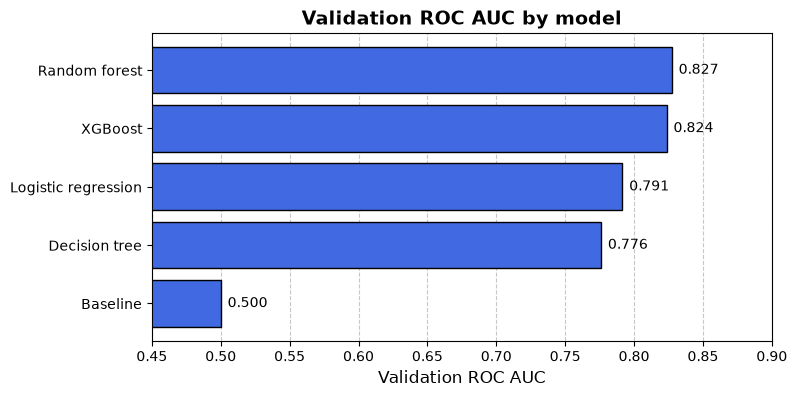

In [ ]:
# Validation AUC of each model
plt.figure(figsize=(8, 4))
plt.barh(comparison_results["model"], comparison_results["roc_auc"], color="royalblue", edgecolor="black", zorder=2)
for i, auc in enumerate(comparison_results["roc_auc"]):
    plt.text(auc + 0.005, i, f"{auc:.3f}", va="center")
plt.gca().invert_yaxis()
plt.xlim(0.45, 0.9)
plt.title("Validation ROC AUC by model", fontsize=14, fontweight="bold")
plt.xlabel("Validation ROC AUC", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7, zorder=1)
plt.show()

### Stability across validation splits

A single validation set of 248 rows is noisy. To check whether the ranking holds, the four chosen configurations are trained and evaluated on five different grouped splits of the training and validation data (`df_full_train`), so that each row is used for validation exactly once.

In [ ]:
# The four chosen configurations on 5 grouped splits of train + validation
cv_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
model_names = [name for name in best if name != "Baseline"]

rows = []
for fold, (fold_train_idx, fold_val_idx) in enumerate(
        cv_splitter.split(df_full_train, y_full_train, groups_full_train), start=1):
    for name in model_names:
        results = evaluate(clone(best[name]["model"]),
                           df_full_train.iloc[fold_train_idx], y_full_train.iloc[fold_train_idx],
                           df_full_train.iloc[fold_val_idx], y_full_train.iloc[fold_val_idx], features)
        rows.append({"fold": fold, "model": name, **results})

cv_results = pd.DataFrame(rows)

cv_summary = cv_results.groupby("model")[METRICS].agg(["mean", "std"]).sort_values(("roc_auc", "mean"), ascending=False)
display(cv_summary.round(3))

roc_auc        accuracy        f1_score       
                       mean    std     mean    std     mean    std
model                                                             
Random forest         0.811  0.038    0.738  0.035    0.697  0.045
XGBoost               0.806  0.048    0.749  0.037    0.721  0.043
Logistic regression   0.802  0.049    0.737  0.039    0.697  0.049
Decision tree         0.776  0.047    0.734  0.052    0.695  0.080

model,Logistic regression,Decision tree,Random forest,XGBoost
fold,,,,
1,0.824,0.828,0.840,0.858
2,0.861,0.810,0.851,0.829
3,0.792,0.721,0.785,0.743
4,0.727,0.735,0.759,0.771
5,0.804,0.787,0.819,0.831


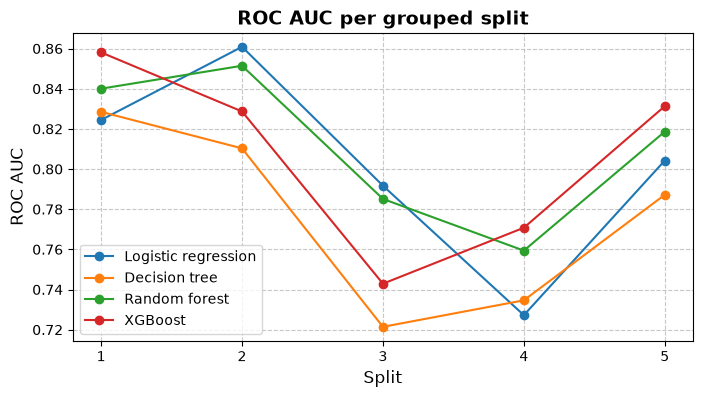

In [ ]:
# AUC of each model in each split
cv_auc = cv_results.pivot(index="fold", columns="model", values="roc_auc")[model_names]
display(cv_auc.round(3))

cv_auc.plot(marker="o", figsize=(8, 4))
plt.title("ROC AUC per grouped split", fontsize=14, fontweight="bold")
plt.xlabel("Split", fontsize=12)
plt.ylabel("ROC AUC", fontsize=12)
plt.xticks(cv_auc.index)
plt.grid(linestyle="--", alpha=0.7)
plt.legend(loc="lower left")
plt.show()

**Conclusion:** The random forest is chosen as the final model, because it has the best ROC AUC, the main metric, in both estimates: 0.827 on the validation set and 0.811 ± 0.038 on average over the five grouped splits, where it is also the most stable model (lowest standard deviation). XGBoost is very close (0.824 and 0.806 ± 0.048) and wins in 3 of the 5 splits, so the two ensembles are practically tied, but there is no reason to prefer it on the main metric. Logistic regression (0.802 on average) and the decision tree (0.776) stay below the two ensembles, and all models are far above the baseline (0.500).

## Final evaluation

The chosen random forest is retrained on the training and validation sets together (988 rows) and evaluated once on the test set (247 rows), which has not been used for any decision so far.

In [ ]:
# Retrain the chosen model on train + validation and evaluate it once on the test set
final_model = make_rf(200, 10, 5)
final_results = evaluate(final_model, df_full_train, y_full_train, df_test, y_test, features)

print_metrics("Random forest on the test set", final_results)

Random forest on the test set: roc_auc 0.761, accuracy 0.725, f1_score 0.657


In [ ]:
# Test result next to the validation and five-split estimates
estimates = pd.DataFrame({
    "validation": {metric: best["Random forest"][metric] for metric in METRICS},
    "5 splits (mean)": cv_summary.xs("mean", axis=1, level=1).loc["Random forest"],
    "5 splits (min)": cv_results[cv_results["model"] == "Random forest"][METRICS].min(),
    "test": final_results,
}).T
display(estimates.round(3))

,roc_auc,accuracy,f1_score
validation,0.827,0.758,0.727
5 splits (mean),0.811,0.738,0.697
5 splits (min),0.759,0.692,0.639
test,0.761,0.725,0.657


In [ ]:
# Composition of the test set: number of groups and weight of the largest one
test_group_sizes = groups_test.value_counts()

print(f"Rows: {len(df_test)}, hospital_number values: {groups_test.nunique()}")
print(f"Largest group: {test_group_sizes.max()} rows ({test_group_sizes.max() / len(df_test):.0%} of the test set)")

Rows: 247, hospital_number values: 56
Largest group: 46 rows (19% of the test set)


In [ ]:
# Confusion matrix on the test set at the 0.5 threshold
y_test_pred = final_model.predict_proba(to_dicts(df_test, features))[:, 1] >= 0.5

confusion = pd.crosstab(
    y_test.map({0: "not lived", 1: "lived"}).rename("actual"),
    pd.Series(y_test_pred).map({False: "not lived", True: "lived"}).rename("predicted"),
)
display(confusion)

predicted,lived,not lived
actual,,
lived,65,49
not lived,19,114


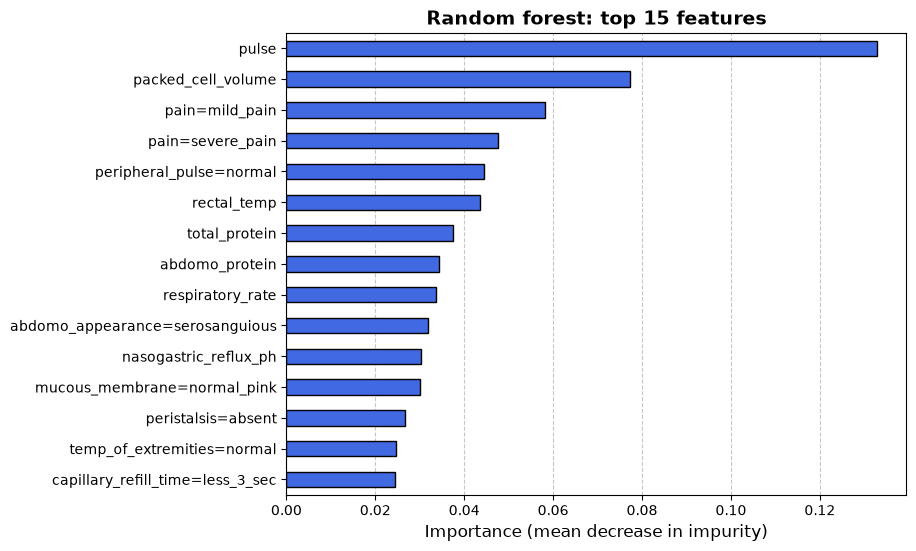

,importance
pulse,0.133
packed_cell_volume,0.077
pain=mild_pain,0.058
pain=severe_pain,0.048
peripheral_pulse=normal,0.044
rectal_temp,0.044
total_protein,0.038
abdomo_protein,0.034
respiratory_rate,0.034
abdomo_appearance=serosanguious,0.032


In [ ]:
# Feature importance of the final model (top 15 one-hot encoded features)
feature_names = final_model.named_steps["dictvectorizer"].get_feature_names_out()
importance = pd.Series(final_model[-1].feature_importances_, index=feature_names).nlargest(15)

importance.sort_values().plot(kind="barh", color="royalblue", edgecolor="black", figsize=(8, 6), zorder=2)
plt.title("Random forest: top 15 features", fontsize=14, fontweight="bold")
plt.xlabel("Importance (mean decrease in impurity)", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7, zorder=1)
plt.show()

display(importance.round(3).to_frame("importance"))

**Conclusion:** On the test set the random forest reaches a ROC AUC of 0.761, an accuracy of 0.725 and an F1 of 0.657. This is clearly better than the baseline (AUC 0.5, accuracy 0.536), but below the validation estimate (0.827) and the five-split mean (0.811), at the level of the weakest of the five splits (0.759). The gap is consistent with how noisy a single small test set is here: its 247 rows come from only 56 `hospital_number` values, and one of them alone accounts for 46 rows (19% of the test set), so the variants of a single case weigh heavily on the score. A fair reading is that the model's expected AUC on new horses lies roughly between 0.76 and 0.83.

At the 0.5 threshold the model is more reliable when it predicts that a horse will not survive: it identifies 114 of the 133 horses that did not live (86%) but only 65 of the 114 that lived (57%). When it predicts survival it is right in 65 of 84 cases (77%), so it tends to be cautious and underestimates survival.

The most important features agree with the EDA: `pulse` and `packed_cell_volume` lead by a wide margin, followed by the pain level, a normal peripheral pulse, serosanguinous abdominal fluid, normal pink mucous membranes and absent gut sounds. Numerical features such as `total_protein` or `abdomo_protein` rank higher here than in the EDA because impurity-based importance favours continuous features, which offer many possible split points, while each categorical feature is spread over several one-hot columns.

## Conclusions

### Data

- The binary target groups `died` and `euthanized` as `not lived` (53.5%) against `lived` (46.5%), so the classes are nearly balanced.
- Identifiers, `cp_data` and the four columns only known after surgery or autopsy are excluded. `surgery` is also excluded: it adds no predictive value (validation AUC 0.752 without it against 0.751 with it) and is usually not decided at admission. The model uses 20 features.
- Missing values, stored as `None` in the CSV, are kept as an `"unknown"` category, since a missing test is associated with the outcome. Five rare categories, artefacts of the synthetic generation, are merged into existing ones, and the 280 `total_protein` values recorded in g/L are converted to g/dL.

### Validation

- `hospital_number` repeats heavily (255 values for 1,235 rows), so the data is split 60/20/20 into train, validation and test with `StratifiedGroupKFold`, keeping every value in a single set. A random split gives a higher, more optimistic AUC (0.773 against 0.751 for the base model).

### Model selection

| Model | Chosen hyperparameters | Validation AUC | Mean AUC on 5 grouped splits |
|---|---|---|---|
| Random forest | `n_estimators=200, max_depth=10, min_samples_leaf=5` | 0.827 | 0.811 ± 0.038 |
| XGBoost | `learning_rate=0.05, max_depth=3, min_child_weight=10, n_estimators=200` | 0.824 | 0.806 ± 0.048 |
| Logistic regression | `C=0.001` | 0.791 | 0.802 ± 0.049 |
| Decision tree | `max_depth=3, min_samples_leaf=20` | 0.776 | 0.776 ± 0.047 |
| Baseline | most frequent class | 0.500 | – |

The random forest is chosen because it has the best ROC AUC in both estimates. XGBoost is practically tied with it.

### Final result

Retrained on train and validation, the random forest reaches a **ROC AUC of 0.761, an accuracy of 0.725 and an F1 of 0.657 on the test set**. The test score is at the lower end of the range seen across splits, partly because one `hospital_number` group makes up 19% of the test rows.